In [1]:
# Install dependencies for image classification evaluation
!pip install -q ultralytics transformers torch torchvision scikit-learn pandas matplotlib seaborn tqdm pillow

In [7]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive")

# Define project directories
PROJECT_DIR = Path("/content/drive/MyDrive/KoraAI")
DATASET_DIR = PROJECT_DIR / "vision" / "test_images"
MODEL_DIR = PROJECT_DIR / "models" / "food_segmentation"

# Define model and catalog paths
YOLO_MODEL_PATH = MODEL_DIR / "best.pt"
CATALOG_PATH = PROJECT_DIR / "vision" / "food_catalog.md"

# Verify required files and directories
assert DATASET_DIR.exists(), "Dataset directory not found!"
assert YOLO_MODEL_PATH.exists(), "YOLO model weights not found!"
assert CATALOG_PATH.exists(), "Food catalog not found!"

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("DATASET DIRECTORY:", DATASET_DIR)
print("YOLO MODEL:", YOLO_MODEL_PATH)
print("FOOD CATALOG:", CATALOG_PATH)

print("\nEnvironment configured successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT DIRECTORY: /content/drive/MyDrive/KoraAI
DATASET DIRECTORY: /content/drive/MyDrive/KoraAI/vision/test_images
YOLO MODEL: /content/drive/MyDrive/KoraAI/models/food_segmentation/best.pt
FOOD CATALOG: /content/drive/MyDrive/KoraAI/vision/food_catalog.md

Environment configured successfully!


In [11]:
import re

# Read the food catalog
catalog_text = CATALOG_PATH.read_text(encoding="utf-8")

# Extract all Markdown bullet items
food_catalog = []

for line in catalog_text.splitlines():
    match = re.match(r"^\s*[-*]\s+(.+?)\s*$", line)

    if match:
        food_catalog.append(match.group(1).strip())

# Keep only the 97 original food categories
food_catalog = list(dict.fromkeys(food_catalog))[:97]

# Verify catalog
print("FOOD CATALOG LOADED")
print("-------------------")
print("Total food categories:", len(food_catalog))

assert len(food_catalog) == 97, "Food catalog must contain 97 categories!"

print("\nCatalog verified successfully!")

FOOD CATALOG LOADED
-------------------
Total food categories: 97

Catalog verified successfully!


In [12]:
from ultralytics import YOLO

# Load the pretrained food segmentation model
yolo_model = YOLO(str(YOLO_MODEL_PATH))

# Verify model configuration
print("YOLO MODEL LOADED")
print("-----------------")
print("Task:", yolo_model.task)
print("Number of classes:", len(yolo_model.names))
print("Classes:", yolo_model.names)

assert yolo_model.task == "segment"
assert len(yolo_model.names) == 1

print("\nYOLO model ready for food region extraction!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO MODEL LOADED
-----------------
Task: segment
Number of classes: 1
Classes: {0: 'food'}

YOLO model ready for food region extraction!


In [13]:
import torch
from transformers import (
    ViTForImageClassification,
    ViTImageProcessor,
    CLIPModel,
    CLIPProcessor
)

# Select the available execution device
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Define pretrained model identifiers
VIT_MODEL_ID = "google/vit-base-patch16-224"
CLIP_MODEL_ID = "openai/clip-vit-base-patch32"

# Load ViT classification model and processor
vit_processor = ViTImageProcessor.from_pretrained(VIT_MODEL_ID)
vit_model = ViTForImageClassification.from_pretrained(VIT_MODEL_ID)
vit_model.to(DEVICE)
vit_model.eval()

# Load CLIP model and processor
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_ID)
clip_model.to(DEVICE)
clip_model.eval()

# Display model information
print("CLASSIFICATION MODELS LOADED")
print("----------------------------")
print("Execution device:", DEVICE)
print("ViT model:", VIT_MODEL_ID)
print("CLIP model:", CLIP_MODEL_ID)

print("\nBoth classification models are ready!")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

... (8 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLASSIFICATION MODELS LOADED
----------------------------
Execution device: cpu
ViT model: google/vit-base-patch16-224
CLIP model: openai/clip-vit-base-patch32

Both classification models are ready!


In [14]:

import pandas as pd

# Load image annotations
ANNOTATIONS_PATH = DATASET_DIR / "annotations" / "annotations.csv"
annotations = pd.read_csv(ANNOTATIONS_PATH)

# Select only single-food images
fruit_data = annotations[
    annotations["scenario"] == "single_food"
].copy()

# Display dataset information
print("SINGLE-FOOD DATASET")
print("-------------------")
print("Total images:", len(fruit_data))
print("Unique categories:", fruit_data["food_items"].nunique())

print("\nImages per category:")
print(fruit_data["food_items"].value_counts().sort_index())

# Verify image files
IMAGE_DIR = DATASET_DIR / "single_food"

fruit_data["image_path"] = fruit_data["file_name"].apply(
    lambda name: str(IMAGE_DIR / name)
)

fruit_data["file_exists"] = fruit_data["image_path"].apply(
    lambda path: Path(path).exists()
)

print("\nExisting image files:", fruit_data["file_exists"].sum())
print("Missing image files:", (~fruit_data["file_exists"]).sum())

# Validate dataset consistency
assert len(fruit_data) == 220
assert fruit_data["food_items"].nunique() == 22
assert fruit_data["file_exists"].all()

print("\nDataset verified successfully!")


SINGLE-FOOD DATASET
-------------------
Total images: 220
Unique categories: 22

Images per category:
food_items
apple          10
avocado        10
banana         10
bell pepper    10
carrot         10
corn           10
cucumber       10
garlic         10
grape          10
kiwi           10
lemon          10
lime           10
mango          10
onion          10
orange         10
peach          10
pear           10
pineapple      10
potato         10
strawberry     10
tomato         10
watermelon     10
Name: count, dtype: int64

Existing image files: 220
Missing image files: 0

Dataset verified successfully!


In [15]:

from sklearn.model_selection import train_test_split

# Split dataset into training and testing subsets
train_data, test_data = train_test_split(
    fruit_data,
    test_size=0.20,
    random_state=42,
    stratify=fruit_data["food_items"]
)

# Reset dataframe indexes
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

# Display split information
print("DATASET SPLIT")
print("-------------")
print("Training images:", len(train_data))
print("Testing images:", len(test_data))

print("\nTraining images per category:")
print(train_data["food_items"].value_counts().sort_index())

print("\nTesting images per category:")
print(test_data["food_items"].value_counts().sort_index())

# Verify split consistency
assert len(train_data) == 176
assert len(test_data) == 44
assert set(train_data["food_items"]) == set(test_data["food_items"])

print("\nDataset split completed successfully!")


DATASET SPLIT
-------------
Training images: 176
Testing images: 44

Training images per category:
food_items
apple          8
avocado        8
banana         8
bell pepper    8
carrot         8
corn           8
cucumber       8
garlic         8
grape          8
kiwi           8
lemon          8
lime           8
mango          8
onion          8
orange         8
peach          8
pear           8
pineapple      8
potato         8
strawberry     8
tomato         8
watermelon     8
Name: count, dtype: int64

Testing images per category:
food_items
apple          2
avocado        2
banana         2
bell pepper    2
carrot         2
corn           2
cucumber       2
garlic         2
grape          2
kiwi           2
lemon          2
lime           2
mango          2
onion          2
orange         2
peach          2
pear           2
pineapple      2
potato         2
strawberry     2
tomato         2
watermelon     2
Name: count, dtype: int64

Dataset split completed successfully!


In [17]:

import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

# Extract visual features using ViT
def extract_vit_features(dataframe):
    features = []
    labels = []

    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe)):
        # Load and preprocess image
        image = Image.open(row["image_path"]).convert("RGB")
        inputs = vit_processor(images=image, return_tensors="pt")
        inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

        # Extract features from the ViT backbone
        with torch.no_grad():
            outputs = vit_model.vit(**inputs)
            image_features = outputs.last_hidden_state[:, 0, :]

        features.append(image_features.cpu().numpy()[0])
        labels.append(row["food_items"])

    return np.array(features), np.array(labels)


# Extract features for training and testing images
X_train_vit, y_train = extract_vit_features(train_data)
X_test_vit, y_test = extract_vit_features(test_data)

# Display extracted feature information
print("VIT FEATURE EXTRACTION")
print("----------------------")
print("Training features:", X_train_vit.shape)
print("Testing features:", X_test_vit.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Verify feature extraction
assert X_train_vit.shape == (176, 768)
assert X_test_vit.shape == (44, 768)

print("\nViT features extracted successfully!")


  0%|          | 0/176 [00:00<?, ?it/s]

  0%|          | 0/44 [00:00<?, ?it/s]

VIT FEATURE EXTRACTION
----------------------
Training features: (176, 768)
Testing features: (44, 768)
Training labels: (176,)
Testing labels: (44,)

ViT features extracted successfully!


In [19]:

import torch.nn.functional as F

# Extract visual features using CLIP
def extract_clip_features(dataframe):
    features = []
    labels = []

    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe)):
        # Load and preprocess image
        image = Image.open(row["image_path"]).convert("RGB")
        inputs = clip_processor(images=image, return_tensors="pt")
        inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

        # Extract and project visual features
        with torch.no_grad():
            vision_outputs = clip_model.vision_model(
                pixel_values=inputs["pixel_values"]
            )

            image_features = clip_model.visual_projection(
                vision_outputs.pooler_output
            )

            # Normalize feature vectors
            image_features = F.normalize(image_features, p=2, dim=-1)

        features.append(image_features.cpu().numpy()[0])
        labels.append(row["food_items"])

    return np.array(features), np.array(labels)


# Extract features for training and testing images
X_train_clip, y_train_clip = extract_clip_features(train_data)
X_test_clip, y_test_clip = extract_clip_features(test_data)

# Display extracted feature information
print("CLIP FEATURE EXTRACTION")
print("-----------------------")
print("Training features:", X_train_clip.shape)
print("Testing features:", X_test_clip.shape)
print("Training labels:", y_train_clip.shape)
print("Testing labels:", y_test_clip.shape)

# Verify feature extraction
assert X_train_clip.shape == (176, 512)
assert X_test_clip.shape == (44, 512)
assert np.array_equal(y_train, y_train_clip)
assert np.array_equal(y_test, y_test_clip)

print("\nCLIP features extracted successfully!")


  0%|          | 0/176 [00:00<?, ?it/s]

  0%|          | 0/44 [00:00<?, ?it/s]

CLIP FEATURE EXTRACTION
-----------------------
Training features: (176, 512)
Testing features: (44, 512)
Training labels: (176,)
Testing labels: (44,)

CLIP features extracted successfully!


In [20]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Create the same classifier pipeline for both models
def create_classifier():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="linear", C=1.0))
    ])


# Train ViT classifier
vit_classifier = create_classifier()
vit_classifier.fit(X_train_vit, y_train)

# Train CLIP classifier
clip_classifier = create_classifier()
clip_classifier.fit(X_train_clip, y_train_clip)

# Display training information
print("CLASSIFIER TRAINING")
print("-------------------")
print("ViT classifier: trained")
print("CLIP classifier: trained")
print("Classifier algorithm: Linear SVM")
print("Regularization parameter (C): 1.0")
print("Training images per model:", len(y_train))

# Verify trained classifiers
assert len(vit_classifier.classes_) == 22
assert len(clip_classifier.classes_) == 22

print("\nBoth classifiers trained successfully!")


CLASSIFIER TRAINING
-------------------
ViT classifier: trained
CLIP classifier: trained
Classifier algorithm: Linear SVM
Regularization parameter (C): 1.0
Training images per model: 176

Both classifiers trained successfully!


In [21]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# Generate predictions on the test dataset
vit_predictions = vit_classifier.predict(X_test_vit)
clip_predictions = clip_classifier.predict(X_test_clip)

# Calculate evaluation metrics
def evaluate_classifier(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }


# Evaluate both classifiers
vit_metrics = evaluate_classifier("ViT", y_test, vit_predictions)
clip_metrics = evaluate_classifier("CLIP", y_test, clip_predictions)

# Create comparison table
comparison_df = pd.DataFrame([vit_metrics, clip_metrics])

print("CLASSIFICATION MODEL COMPARISON")
print("--------------------------------")
display(comparison_df.round(4))

# Display detailed classification reports
print("\nVIT CLASSIFICATION REPORT")
print(classification_report(
    y_test, vit_predictions, zero_division=0
))

print("\nCLIP CLASSIFICATION REPORT")
print(classification_report(
    y_test, clip_predictions, zero_division=0
))

# Verify evaluation results
assert len(vit_predictions) == 44
assert len(clip_predictions) == 44

print("Both models evaluated successfully!")


CLASSIFICATION MODEL COMPARISON
--------------------------------


,Model,Accuracy,Precision,Recall,F1-score
0,ViT,0.9773,0.9848,0.9773,0.9758
1,CLIP,0.9545,0.9697,0.9545,0.9515



VIT CLASSIFICATION REPORT
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00         2
     avocado       1.00      1.00      1.00         2
      banana       1.00      1.00      1.00         2
 bell pepper       0.67      1.00      0.80         2
      carrot       1.00      1.00      1.00         2
        corn       1.00      1.00      1.00         2
    cucumber       1.00      1.00      1.00         2
      garlic       1.00      1.00      1.00         2
       grape       1.00      1.00      1.00         2
        kiwi       1.00      1.00      1.00         2
       lemon       1.00      1.00      1.00         2
        lime       1.00      1.00      1.00         2
       mango       1.00      1.00      1.00         2
       onion       1.00      1.00      1.00         2
      orange       1.00      1.00      1.00         2
       peach       1.00      1.00      1.00         2
        pear       1.00      1.00      1.00         2


In [22]:

# Create a dataframe with classification predictions
error_analysis = pd.DataFrame({
    "file_name": test_data["file_name"].values,
    "true_label": y_test,
    "vit_prediction": vit_predictions,
    "clip_prediction": clip_predictions
})

# Identify incorrect predictions from each model
error_analysis["vit_correct"] = (
    error_analysis["true_label"] == error_analysis["vit_prediction"]
)

error_analysis["clip_correct"] = (
    error_analysis["true_label"] == error_analysis["clip_prediction"]
)

# Display incorrect predictions
print("VIT MISCLASSIFICATIONS")
print("----------------------")
display(
    error_analysis[~error_analysis["vit_correct"]]
)

print("\nCLIP MISCLASSIFICATIONS")
print("-----------------------")
display(
    error_analysis[~error_analysis["clip_correct"]]
)

# Compare model performance on individual images
print("\nIMAGE-LEVEL COMPARISON")
print("----------------------")
display(
    error_analysis[
        error_analysis["vit_correct"] != error_analysis["clip_correct"]
    ]
)

print("\nError analysis completed!")


VIT MISCLASSIFICATIONS
----------------------


,file_name,true_label,vit_prediction,clip_prediction,vit_correct,clip_correct
9,IMG_207.jpg,tomato,bell pepper,tomato,False,True



CLIP MISCLASSIFICATIONS
-----------------------


,file_name,true_label,vit_prediction,clip_prediction,vit_correct,clip_correct
1,IMG_167.jpg,pear,pear,banana,True,False
25,IMG_151.jpg,peach,peach,apple,True,False



IMAGE-LEVEL COMPARISON
----------------------


,file_name,true_label,vit_prediction,clip_prediction,vit_correct,clip_correct
1,IMG_167.jpg,pear,pear,banana,True,False
9,IMG_207.jpg,tomato,bell pepper,tomato,False,True
25,IMG_151.jpg,peach,peach,apple,True,False



Error analysis completed!


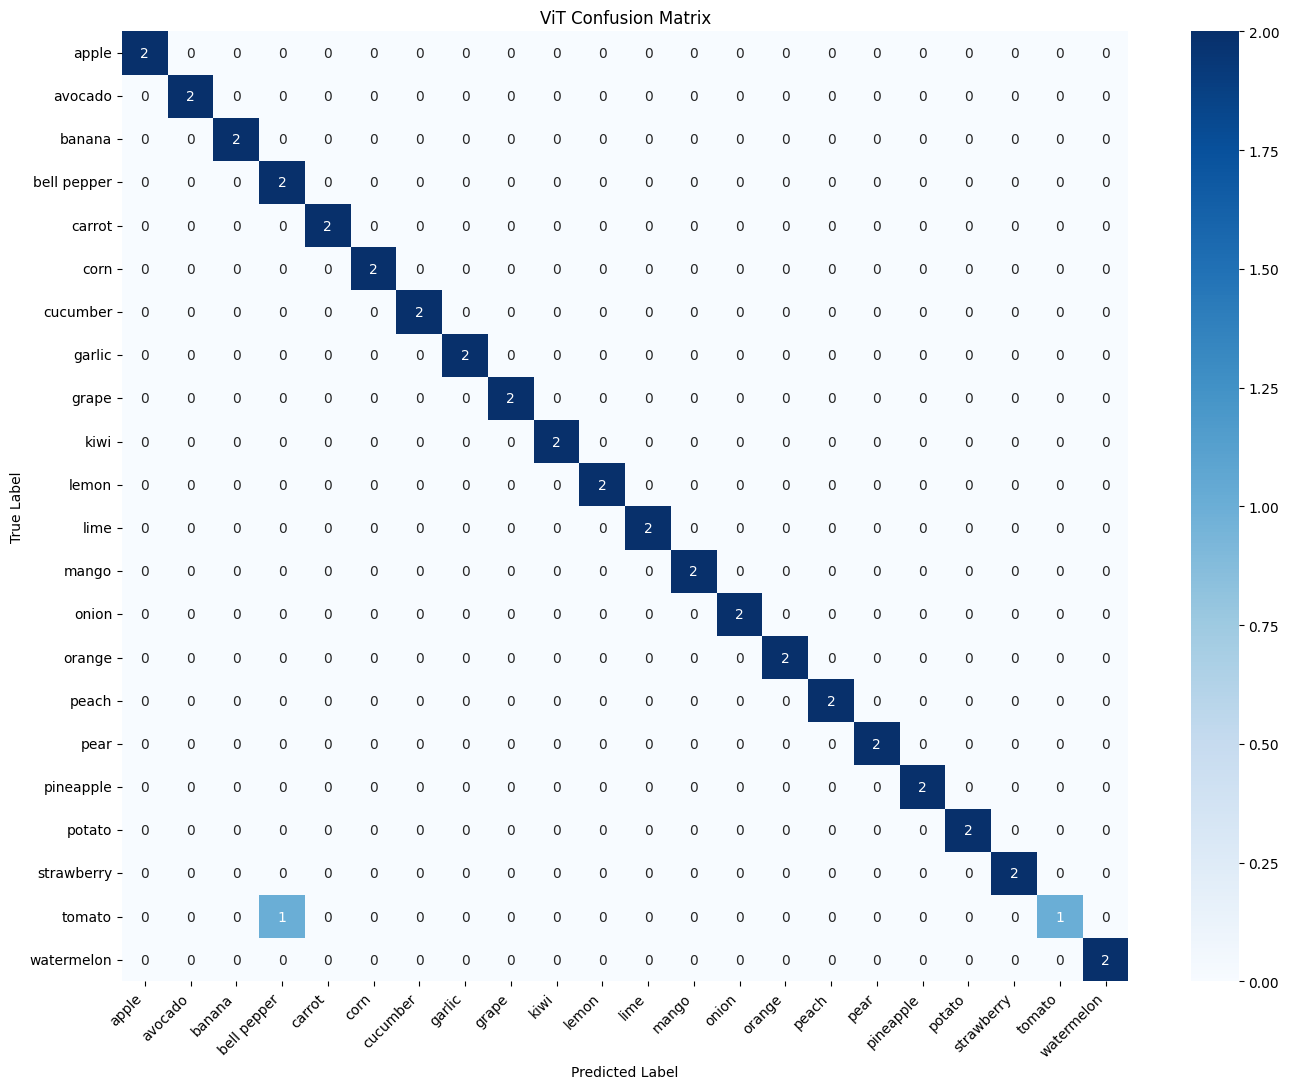

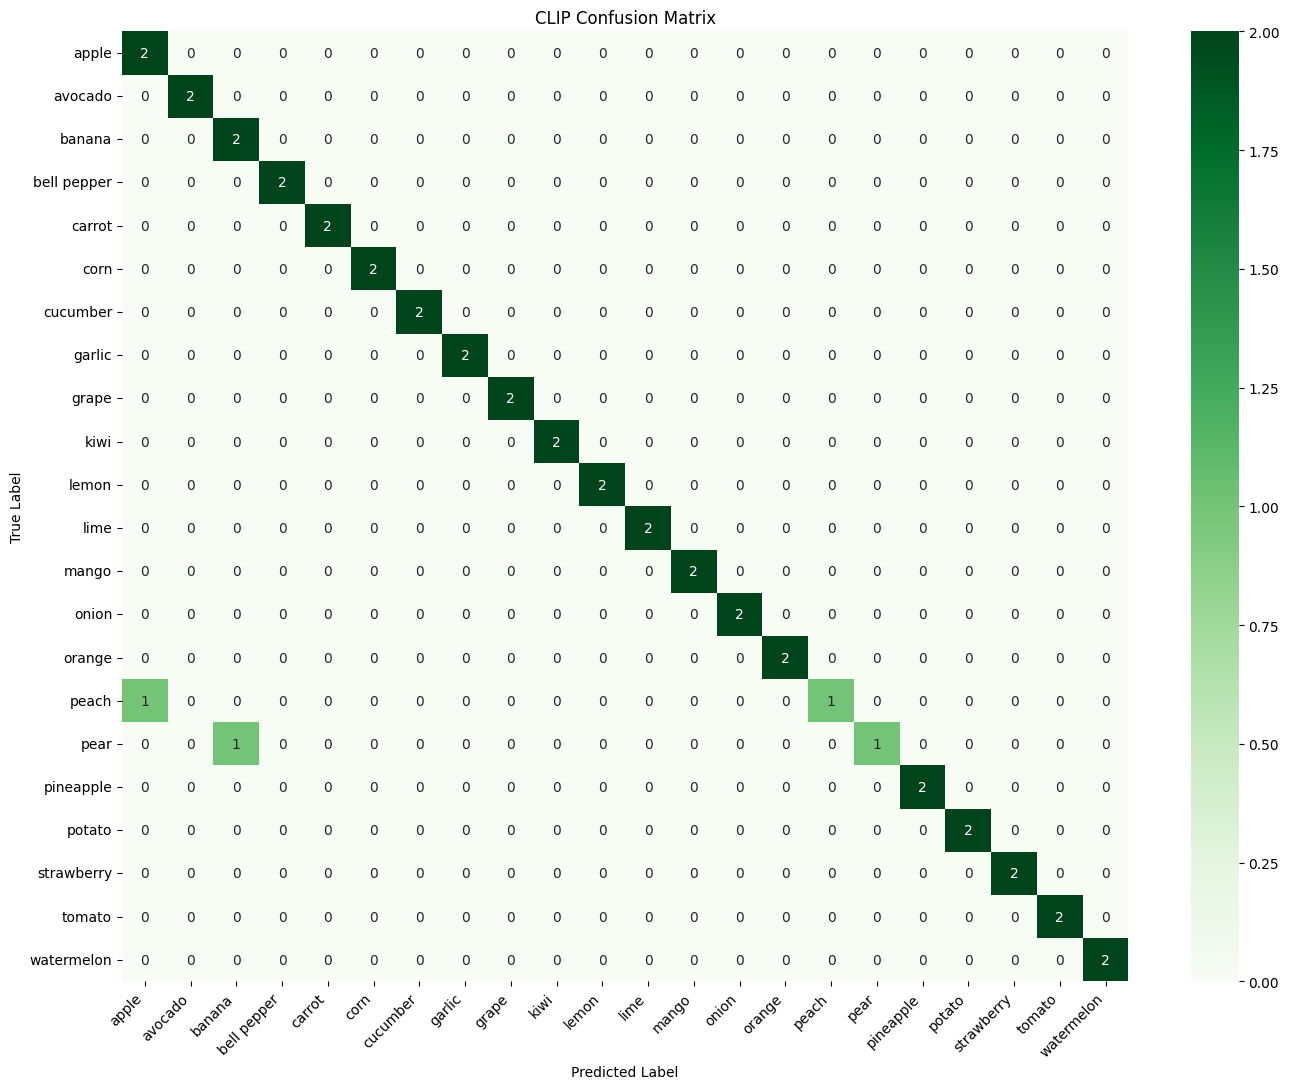

Confusion matrices generated successfully!


In [23]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Define category labels
class_labels = sorted(np.unique(y_test))

# Generate confusion matrices
vit_cm = confusion_matrix(
    y_test, vit_predictions, labels=class_labels
)

clip_cm = confusion_matrix(
    y_test, clip_predictions, labels=class_labels
)

# Plot ViT confusion matrix
plt.figure(figsize=(14, 11))
sns.heatmap(
    vit_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("ViT Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Plot CLIP confusion matrix
plt.figure(figsize=(14, 11))
sns.heatmap(
    clip_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("CLIP Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Confusion matrices generated successfully!")


In [24]:

# Define the evaluation results directory
RESULTS_DIR = PROJECT_DIR / "vision" / "classification_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save model comparison metrics
comparison_df.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

# Save individual classification predictions
error_analysis.to_csv(
    RESULTS_DIR / "classification_predictions.csv",
    index=False
)

# Save detailed classification reports
with open(
    RESULTS_DIR / "classification_reports.txt",
    "w",
    encoding="utf-8"
) as report_file:

    report_file.write("VIT CLASSIFICATION REPORT\n")
    report_file.write(
        classification_report(y_test, vit_predictions, zero_division=0)
    )

    report_file.write("\nCLIP CLASSIFICATION REPORT\n")
    report_file.write(
        classification_report(y_test, clip_predictions, zero_division=0)
    )

# Display saved files
print("CLASSIFICATION RESULTS SAVED")
print("-----------------------------")

for file_path in RESULTS_DIR.iterdir():
    print(file_path.name)

print("\nResults saved successfully!")


CLASSIFICATION RESULTS SAVED
-----------------------------
model_comparison.csv
classification_predictions.csv
classification_reports.txt

Results saved successfully!
